In [11]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

microtorch_model = ModelMaker("Ball")

sphere = ModelMaker("Sphere")
sphere.fixed_D = 2

sphere_model = MicrotorchTissueModel(
    sphere,
    parameters={"radius": 6.0},
)

# Wrap each compartment individually, not the combined ModelMaker model.

ball_model = MicrotorchTissueModel(
    microtorch_model,
    parameters={"D": 2},
)



ball_relax = RelaxationTissueModel(ball_model, t2=100e-3)
sphere_relax = RelaxationTissueModel(sphere_model, t2 = 50e-3)


model = MultiTissueModel(
    [sphere_relax, ball_relax],
    volume_fractions=[0.6, 0.4],
)

#model["model_0_T2"].scale = 1
#model["model_1_T2"].scale = 1

model["vf_0"].fit_flag = True

model["model_1_model_D"].optimize = False
model["model_1_model_D"].fit_flag = False

model["vf_1"].optimize = False
model["vf_1"].fit_flag = False

model["S0"].optimize = False
model["S0"].fit_flag = False

model["model_0_T2"].optimize = False
model["model_0_T2"].fit_flag = False
model["model_1_T2"].optimize = False
model["model_1_T2"].fit_flag = False

print(model)

No YAML configuration found for Ball model.
Falling back to parsing model name for compartments: ['Ball'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Ball
########### Compartments: ['Ball']
########### Parameter names: [['D']]
########### Parameter ranges: [[[0.001, 3]]]
-----------
No YAML configuration found for Sphere model.
Falling back to parsing model name for compartments: ['Sphere'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Sphere
########### Compartments: ['Sphere']
########### Parameter names: [['radius']]
########### Parameter ranges: [[[0.001, 15]]]
-----------
Tissue model with 7 scalar parameters:
Tissue-parameter        Value    Scale  Optimize    Fit    Fit Bounds
--------------------  -------  -------  ----------  -----  -------------
model_0_model_radius     6       1      True        True   (0.001, 15.0)
model_0_T2               0.05    0.001  False       False

In [12]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 6
block_size = n_directions + 1  # b0 + n_directions

# shell_bvals = [1500, 1000, 2200, 2500, 2500]
# shell_deltas = [0.0258, 0.0205,0.0205,0.0334, 0.0334]
# shell_Deltas = [0.0434, 0.0431,0.0431, 0.0455, 0.0455]
# initial_te = 0.09


shell_bvals = [2999, 2000, 1500, 500, 90, 150]
shell_deltas = [0.0247, 0.0132, 0.0247, 0.0122, 0.0122, 0.011]
shell_Deltas = [0.0438, 0.0323, 0.0434, 0.0313, 0.0238, 0.020]
initial_te = [0.090, 0.067, 0.090, 0.065, 0.050, 0.040]
# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# One optimized TE, delta, and Delta per shell, shared across that shell's
# b0 and diffusion-weighted measurements.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Keep each b0 gradient magnitude fixed at zero.
# All diffusion-weighted gradient magnitudes remain independently optimizable.
b0_mask = np.isclose(b_vals, 0.0)
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)

magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

# Check the masks and b0 values.
print("Timing free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Gradient-magnitude free indices:",
      np.flatnonzero(magnitude.optimize_mask))
print("b0 gradient magnitudes:", magnitude.values[b0_mask])

assert np.all(magnitude.values[b0_mask] == 0.0)
assert not np.any(magnitude.optimize_mask[b0_mask])

print(magnitude.optimize_mask)
print(initial_scheme)


Timing free indices: [ 0  7 14 21 28 35]
Gradient-magnitude free indices: [ 1  8 15 22 29 36]
b0 gradient magnitudes: [-0. -0. -0. -0. -0. -0.]
[False  True False False False False False False  True False False False
 False False False  True False False False False False False  True False
 False False False False False  True False False False False False False
  True False False False False False]
Acquisition scheme with 42 measurements and 6 scalar parameters. 
total number of optimized parameters is 24:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -

In [13]:
jacobian = model.scaled_jacobian(initial_scheme)
print(jacobian)

[[ 0.         -0.24127077]
 [-0.00844032  0.1386998 ]
 [-0.00844032  0.1386998 ]
 [-0.00844032  0.1386998 ]
 [-0.00844032  0.1386998 ]
 [-0.00844032  0.1386998 ]
 [-0.00844032  0.1386998 ]
 [ 0.         -0.24986291]
 [-0.01517503  0.19985432]
 [-0.01517503  0.19985432]
 [-0.01517503  0.19985432]
 [-0.01517503  0.19985432]
 [-0.01517503  0.19985432]
 [-0.01517503  0.19985432]
 [ 0.         -0.24127077]
 [-0.00463791  0.1315764 ]
 [-0.00463791  0.1315764 ]
 [-0.00463791  0.1315764 ]
 [-0.00463791  0.1315764 ]
 [-0.00463791  0.1315764 ]
 [-0.00463791  0.1315764 ]
 [ 0.         -0.24951398]
 [-0.00492048  0.06453341]
 [-0.00492048  0.06453341]
 [-0.00492048  0.06453341]
 [-0.00492048  0.06453341]
 [-0.00492048  0.06453341]
 [-0.00492048  0.06453341]
 [ 0.         -0.23865122]
 [-0.0016627  -0.14414453]
 [-0.0016627  -0.14414453]
 [-0.0016627  -0.14414453]
 [-0.0016627  -0.14414453]
 [-0.0016627  -0.14414453]
 [-0.0016627  -0.14414453]
 [ 0.         -0.22099108]
 [-0.00400752 -0.06105896]
 

In [14]:
import copy
import numpy as np
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme
from microtool.optimize.loss_functions import compute_loss, default_loss

n_runs = 1
noise_variance = 0.02**2
loss_function = default_loss  # or whichever loss function you intend to evaluate

optimization_history = []

for run_idx in range(n_runs):
    print(f"--- Running optimization {run_idx + 1}/{n_runs} ---")
    
    # Instantiate method per run to ensure clean state
    method = methods.SOMA()
    
    # Pass a deep copy of initial_scheme so in-place edits don't contaminate subsequent runs
    scheme_run, opt_info = optimize_scheme(
        copy.deepcopy(initial_scheme),
        model,
        noise_variance=noise_variance,
        method=method,
    )
    
    # Compute the final loss value for this optimized scheme
    current_loss = compute_loss(
        scheme_run,
        model,
        noise_variance,
        loss_function,
    )
    
    optimization_history.append({
        "run": run_idx + 1,
        "scheme": scheme_run,
        "loss": float(current_loss),
        "info": opt_info,
    })
    
    print(f"Run {run_idx + 1} completed with loss: {current_loss:.6e}")

# Find the run with the minimum loss
best_result = min(optimization_history, key=lambda res: res["loss"])
optimal_scheme_SOMA = best_result["scheme"]

print("\n=== Optimization Summary ===")
for res in optimization_history:
    print(f"Run {res['run']}: Loss = {res['loss']:.6e}")

print(f"\nBest Run: #{best_result['run']} with Lowest Loss = {best_result['loss']:.6e}")

--- Running optimization 1/1 ---
[SOMA] Starting Optimization
  Dimension (Nx)     : 24
  Population Size    : 50
  Max Migrations     : 200
  Max Fevals         : 240000
  Jumps per movement : 28
[Init] hit-and-run | Nx=24, target=50, burn_in=2000, thin=100, n_active=None


/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/tissue_model.py:670: UserWarning: If T2 relaxation is not used for fitting, echo time should be fixed.
  warnings.warn("If T2 relaxation is not used for fitting, echo time should be fixed.")


[Init] burn-in 500/2000 | moved=500, stuck=0
[Init] burn-in 1000/2000 | moved=1000, stuck=0
[Init] burn-in 1500/2000 | moved=1500, stuck=0
[Init] burn-in 2000/2000 | moved=2000, stuck=0
[Init]   2/50 | step=2100 | dist from start (rel)=1.184e+00
[Init]   3/50 | step=2200 | dist from start (rel)=1.343e+00
[Init]   4/50 | step=2300 | dist from start (rel)=1.342e+00
[Init]   5/50 | step=2400 | dist from start (rel)=1.420e+00
[Init]   6/50 | step=2500 | dist from start (rel)=1.588e+00
[Init]   7/50 | step=2600 | dist from start (rel)=1.496e+00
[Init]   8/50 | step=2700 | dist from start (rel)=1.480e+00
[Init]   9/50 | step=2800 | dist from start (rel)=1.460e+00
[Init]  10/50 | step=2900 | dist from start (rel)=1.441e+00
[Init]  11/50 | step=3000 | dist from start (rel)=1.445e+00
[Init]  12/50 | step=3100 | dist from start (rel)=1.406e+00
[Init]  13/50 | step=3200 | dist from start (rel)=1.470e+00
[Init]  14/50 | step=3300 | dist from start (rel)=1.579e+00
[Init]  15/50 | step=3400 | dist f

In [15]:
print(optimal_scheme_SOMA)
print(optimal_scheme_SOMA.b_values)

Acquisition scheme with 42 measurements and 6 scalar parameters. 
total number of optimized parameters is 24:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  -------------------------------------------  -------------------------------------------  -----------------------------
                                     -0                                             0.294175                                     1.56733                                     0.0100493                                    0.0205309                      0.0691841
                                      3.12658e-05                                  -2.01224                      

In [17]:
from pathlib import Path
import pickle
from microtool.monte_carlo.IO import make_expirement_directories

# Pass parent directory as cwd / "Ball_T2", experiment as "Shell_3"
plotdir, modeldir, simdir, schemedir = make_expirement_directories(
    Path.cwd() / "Ball_Sphere_T2", "Test"
)
print(schemedir)

# Save schemes and model
with open(schemedir / "initial_scheme.pkl", "wb") as f:
  pickle.dump(initial_scheme, f)

with open(schemedir / "optimal_scheme.pkl", "wb") as f:
  pickle.dump(optimal_scheme_SOMA, f)

with open(modeldir / "model.pkl", "wb") as f:
  pickle.dump(model, f)

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/examples/Ball_Sphere_T2/Test/schemes


In [18]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats
import matplotlib.pyplot as plt


noise_distribution = stats.norm(0, scale=0.02)



# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result
simulation.save(simdir / "initial.pkl")

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme_SOMA)
simulation.run()
optimal = simulation.result
simulation.save(simdir / "optimal.pkl")

Starting Monte Carlo with 1000 simulations:   0%|          | 0/1000 [00:00<?, ?it/s]/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Starting Monte Carlo with 1000 simulations:   0%|          | 1/1000 [00:00<01:56,  8.61it/s]/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
St

Valid fits: initial=1000, optimal=1000

Initial scheme
                          bias      std     RMSE  scaled bias  scaled std  \
model_0_model_radius -0.29212  1.09858  1.13676     -0.04869     0.18310   
vf_0                 -0.09851  0.10201  0.14181     -0.16418     0.17001   

                      scaled RMSE  
model_0_model_radius      0.18946  
vf_0                      0.23635   
TOTAL scaled RMSE: 0.21419

Optimal scheme
                          bias      std     RMSE  scaled bias  scaled std  \
model_0_model_radius -0.17096  0.92347  0.93916     -0.02849     0.15391   
vf_0                 -0.10462  0.10797  0.15034     -0.17437     0.17994   

                      scaled RMSE  
model_0_model_radius      0.15653  
vf_0                      0.25056   
TOTAL scaled RMSE: 0.20891

Improvement of total scaled RMSE: 2.5%


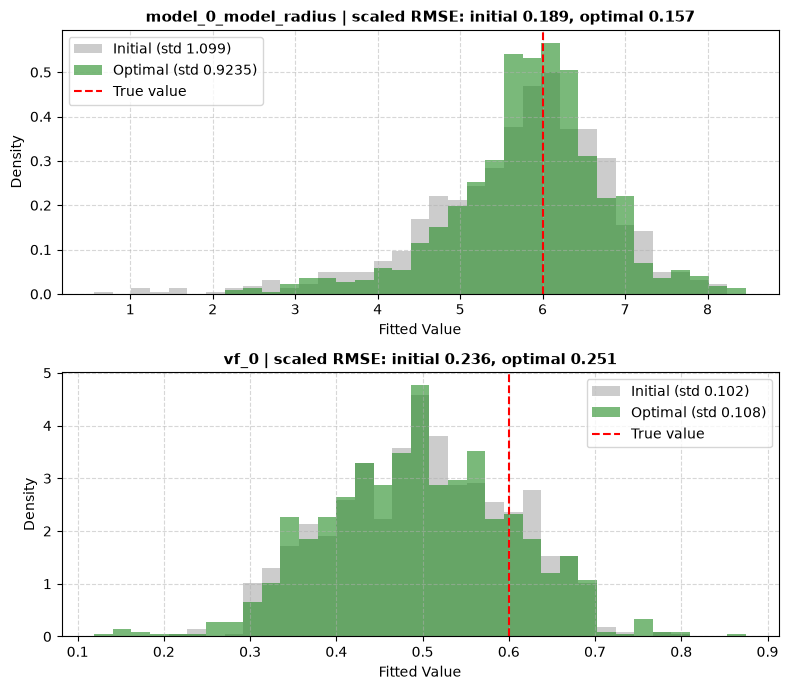

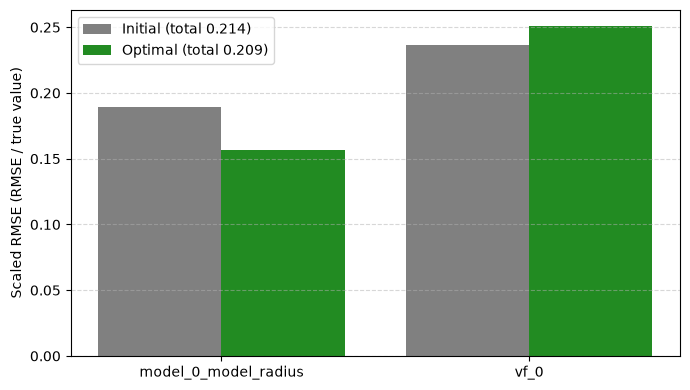

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ data
df_init = pd.DataFrame(initial)
df_opt = pd.DataFrame(optimal)

# ground truth used for the simulation (same units as the fitted columns)
true_values = {
    "model_0_model_radius": 6, 
    "vf_0":      0.6
}
scales = dict(true_values)   # relative RMSE = RMSE / true value

common_cols = [c for c in df_opt.columns if c in df_init.columns and c in true_values]
missing = [c for c in df_opt.columns if c in df_init.columns and c not in true_values]
if missing:
    print(f"Skipping columns without a true value: {missing}")

# drop failed fits (NaN / inf)
df_init = df_init[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
df_opt = df_opt[common_cols].replace([np.inf, -np.inf], np.nan).dropna()
print(f"Valid fits: initial={len(df_init)}, optimal={len(df_opt)}")


# ------------------------------------------------------------------ RMSE
def rmse_table(df):
    rows = {}
    for col in common_cols:
        err = df[col].to_numpy() - true_values[col]
        rmse = np.sqrt(np.mean(err ** 2))
        s = abs(scales[col])
        rows[col] = {
            "bias": err.mean(),
            "std": err.std(),
            "RMSE": rmse,
            "scaled bias": err.mean() / s,
            "scaled std": err.std() / s,
            "scaled RMSE": rmse / s,
        }
    tab = pd.DataFrame(rows).T
    total = np.sqrt(np.mean(tab["scaled RMSE"] ** 2))
    return tab, total


tab_init, total_init = rmse_table(df_init)
tab_opt, total_opt = rmse_table(df_opt)

print("\nInitial scheme\n", tab_init.round(5), f"\nTOTAL scaled RMSE: {total_init:.5f}")
print("\nOptimal scheme\n", tab_opt.round(5), f"\nTOTAL scaled RMSE: {total_opt:.5f}")
print(f"\nImprovement of total scaled RMSE: {100 * (1 - total_opt / total_init):.1f}%")

# ------------------------------------------------------------------ histograms
fig, axes = plt.subplots(
    nrows=len(common_cols), ncols=1, figsize=(8, 3.5 * len(common_cols)), squeeze=False
)

for i, col in enumerate(common_cols):
    ax = axes[i, 0]

    # shared bin edges so both histograms are directly comparable
    both = np.concatenate([df_init[col].to_numpy(), df_opt[col].to_numpy()])
    bins = np.linspace(both.min(), both.max(), 36)

    ax.hist(df_init[col], bins=bins, density=True, alpha=0.4, color="gray",
            label=f"Initial (std {tab_init.loc[col, 'std']:.4g})")
    ax.hist(df_opt[col], bins=bins, density=True, alpha=0.6, color="forestgreen",
            label=f"Optimal (std {tab_opt.loc[col, 'std']:.4g})")
    ax.axvline(true_values[col], color="red", linestyle="--", label="True value")

    ax.set_title(
        f"{col} | scaled RMSE: initial {tab_init.loc[col, 'scaled RMSE']:.3f}, "
        f"optimal {tab_opt.loc[col, 'scaled RMSE']:.3f}",
        fontsize=11, fontweight="bold",
    )
    ax.set_xlabel("Fitted Value")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------ bar plot
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(common_cols))
ax.bar(x - 0.2, tab_init["scaled RMSE"], 0.4, color="gray",
       label=f"Initial (total {total_init:.3f})")
ax.bar(x + 0.2, tab_opt["scaled RMSE"], 0.4, color="forestgreen",
       label=f"Optimal (total {total_opt:.3f})")
ax.set_xticks(x)
ax.set_xticklabels(common_cols)
ax.set_ylabel("Scaled RMSE (RMSE / true value)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5, axis="y")
plt.tight_layout()
plt.show()